# UTS : Sistem Informasi Geografis Menggunakan Piksel

## Klasifikasi Tutupan Lahan (LULC) Provinsi Jawa Timur Menggunakan Citra Sentinel-2A

## 1. Business Understanding

### 1.1 Latar Belakang

Provinsi Jawa Timur merupakan salah satu pusat pertumbuhan ekonomi dan lumbung pangan nasional. Dinamika pembangunan yang pesat memicu terjadinya konversi tutupan lahan secara masif, seperti alih fungsi lahan pertanian (sawah) menjadi area pemukiman atau industri, serta menyusutnya luasan kawasan lindung seperti hutan mangrove di pesisir.

Pemantauan perubahan tutupan lahan (*Land Use and Land Cover* / LULC) menggunakan survei lapangan konvensional memakan biaya besar, waktu yang lama, dan cakupan spasial yang terbatas. Di sisi lain, pemerintah daerah memerlukan data pemetaan yang aktual untuk mengevaluasi **Rencana Tata Ruang Wilayah (RTRW)** dan merumuskan kebijakan tata ruang yang berwawasan lingkungan. Oleh karena itu, diperlukan sebuah pendekatan otomatis berbasis Sistem Informasi Geografis (SIG) yang dipadukan dengan kecerdasan buatan (*Machine Learning*) untuk memetakan kondisi lahan secara cepat, akurat, dan luas.

### 1.2 Tujuan

Proyek analisis spasial ini memiliki beberapa tujuan utama:

1. **Otomatisasi Pemetaan Lahan:** Mengklasifikasikan 6 (enam) kelas tutupan lahan di Jawa Timur secara otomatis menggunakan data citra satelit Sentinel-2A.

2. **Evaluasi Algoritma:** Mencari dan mengimplementasikan algoritma *Machine Learning* dengan akurasi tertinggi untuk membaca pola spektral penggunaan lahan.

3. **Mendukung Kebijakan Spasial:** Menyediakan peta digital aktual yang dapat digunakan sebagai instrumen evaluasi kebijakan tata ruang dan ketahanan pangan (luasan sawah).

4. **Pengembangan Sistem Interaktif:** Men-deploy hasil pemodelan ke dalam aplikasi Web  interaktif (Streamlit) dan dokumentasi komputasi web statis (Jupyter Book) agar mudah diakses oleh para pemangku kepentingan untuk memenuhi tugas UTS matakuliah Proyek Sains Data.

## 2. Data Understanding

### 2.1 Data Collecting

Data yang digunakan dalam analisis ini bukanlah gambar biasa, melainkan data reflektansi spektral yang diekstrak dari **Citra Satelit Sentinel-2A Level-2A**. Proses akuisisi (*data collecting*) dilakukan melalui antrean komputasi *cloud* (Batch Job) di server **Copernicus Data Space Ecosystem (OpenEO)**. 
Citra yang diambil merupakan komposit nilai *median* dari rentang waktu observasi 01 Agustus 2026 hingga 31 Agustus 2026, yang bertujuan untuk menghilangkan gangguan noise dan tutupan awan di wilayah Jawa Timur.

Total Keseluruhan data yang diambil adalah:

``Kelas 'Sawah': 20 poligon`` 
``Kelas 'Bangunan': 20 poligon`` 
``Kelas 'Lahan Hijau': 20 poligon`` 
``Kelas 'Mangrove': 20 poligon``
``Kelas 'Ranu': 20 poligon ``
``Kelas 'Perairan Laut': 20 poligon``

``Jumlah sampel piksel total: 232120``

**Jumlah piksel per kelas:**

``Perairan Laut``    ``205465``
``Lahan Hijau``       ``20092``
``Sawah``              ``3181``
``Bangunan``           ``1679``
``Ranu``               ``1579``
``Mangrove``            ``124``

### 2.2 Deskripsi Dataset dan Label Kelas

Eksperimen ini menggunakan total **120 data titik sampel koordinat** yang didistribusikan secara proporsional ke dalam 6 kelas (masing-masing 20 titik/sampel). Penentuan kelas Klasifikasi Penutup Lahan yang telah disesuaikan dengan lanskap Jawa Timur:

1. **Sawah:** Area lahan basah pertanian.

2. **Bangunan:** Area terbangun, pemukiman, dan infrastruktur padat.

3. **Lahan Hijau:** Vegetasi non-pertanian, hutan daratan, atau ruang terbuka hijau.

4. **Mangrove:** Vegetasi payau di sepanjang pesisir (utara/selatan laut Jawa Timur).

5. **Ranu (Danau):** Badan air tawar tertutup yang tersebar di wilayah Jawa Timur.

6. **Perairan Laut:** Wilayah perairan laut lepas.

Dataset dibagi dengan rasio **80:20**, yaitu 240 sampel untuk melatih (*training*) algoritma pembelajaran mesin dan 60 sampel untuk menguji (*testing*) akurasinya.

### 2.3 Ekstraksi Fitur

Dataset tabular dibentuk dari ekstraksi 7 fitur utama per piksel citra, yang terdiri dari 5 *band* spektral dan 2 indeks transformasi:

**A. Band Spektral Sentinel-2A:**

1.   **B02 (Blue - 490 nm):** Sensitif terhadap pantulan perairan dangkal dan deteksi aerosol atmosfer.

2.   **B03 (Green - 560 nm):** Menangkap puncak pantulan hijau dari klorofil dedaunan.

3.   **B04 (Red - 665 nm):** Menyerap klorofil secara kuat; parameter utama dalam mengidentifikasi tingkat kepadatan vegetasi.

4.   **B08 (NIR / Near-Infrared - 842 nm):** Sangat sensitif terhadap struktur biomassa sel daun. Memiliki nilai yang sangat tinggi pada vegetasi hijau dan diserap habis (nilai 0) pada badan air.

5.   **B11 (SWIR / Shortwave-Infrared - 1610 nm):** Digunakan secara khusus untuk mendeteksi tingkat kelembapan (kandungan air) pada permukaan tanah dan tajuk vegetasi.

**B. Indeks Transformasi (Rumus Spektral):**

Untuk mempermudah algoritma dalam mengenali pola, fitur spektral dasar dikalkulasikan ke dalam dua metrik indeks matematis:

1. **NDVI (*Normalized Difference Vegetation Index*)**
   Mengukur tingkat kehijauan, kerapatan, dan kesehatan vegetasi.
   > **Rumus:** 
   
   $$NDVI = \frac{B08 - B04}{B08 + B04}$$

2. **NDWI (*Normalized Difference Water Index*)**
   Mendeteksi fitur kebasahan dan badan air secara tegas, sembari meminimalisir efek pantulan dari tanah maupun vegetasi terrestrial.
   > **Rumus:** 
   
   $$NDWI = \frac{B03 - B08}{B03 + B08}$$

3. **NDBI (*Normalized Difference Built-up Index*)**

   Digunakan khusus untuk mengidentifikasi dan memetakan area terbangun, pemukiman, serta infrastruktur (kelas Bangunan) dengan memanfaatkan pantulan spektral yang tinggi pada gelombang Shortwave Infrared (SWIR) dibandingkan Near-Infrared (NIR).

   > **Rumus:**
   
   $$NDBI = \frac{B11 - B08}{B11 + B08}$$

4. **MNDWI (*Modified Normalized Difference Water Index*)**

   Penyempurnaan dari indeks air konvensional yang sangat efektif untuk membedakan badan air (seperti Ranu/Danau dan Perairan Laut) dari area pemukiman atau lahan daratan, serta membantu menegaskan batas wilayah genangan air pada lahan basah seperti Sawah dan Mangrove.

   > **Rumus:**
   
   $$MNDWI = \frac{B03 - B11}{B03 + B11}$$

Dengan kombinasi fitur spektral dan indeks vegetasi/air ini, model *Machine Learning* dapat mengenali batasan tegas antara Sawah, Bangunan, Lahan Hijau, Mangrove, Danau, dan Perairan berdasarkan angka matematis.

### Implementasi: Instalasi Library Yang Digunakan

Sistem klasifikasi tutupan lahan ini dibangun menggunakan 5 pustaka utama Python yang saling terintegrasi:

1. **GeoPandas (`geopandas`)**
   Digunakan untuk memproses data vektor spasial, membaca titik sampel koordinat, menyelaraskan sistem referensi koordinat (CRS), dan membuat batas wilayah observasi (*Bounding Box*).

2. **OpenEO (`openeo`)**
   Berfungsi sebagai klien komputasi (*cloud*) untuk terhubung ke server *Copernicus*. Pustaka ini memproses, memfilter awan, dan mengunduh citra satelit Sentinel-2A secara otomatis tanpa membebani komputasi lokal.

3. **Rasterio (`rasterio`)**
   Spesialis pengolah data raster (citra `.tif`). Digunakan untuk membaca matriks gambar satelit dan mengekstrak nilai piksel spektral tepat pada koordinat sampel yang ditentukan oleh GeoPandas.

4. **Scikit-Learn (`sklearn`)**
   Pustaka utama untuk *Machine Learning*. Digunakan untuk membagi *dataset* (latih dan uji), melatih algoritma **Gradient Boosting Classifier**, serta menghitung metrik evaluasi akurasi model.
   
5. **Seaborn (`seaborn`)**
   Pustaka visualisasi data untuk merender hasil evaluasi statistik dan metrik model (seperti *Confusion Matrix*) ke dalam bentuk grafik atau *heatmap* yang estetik dan mudah dianalisis.

### Implementasi : Instalasi Library

In [6]:
pip install geopandas

Note: you may need to restart the kernel to use updated packages.


In [7]:
pip install openeo

Note: you may need to restart the kernel to use updated packages.


In [8]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [9]:
pip install rasterio

Note: you may need to restart the kernel to use updated packages.


In [10]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


### Implementasi : Coleccting Data

In [43]:
import geopandas as gpd
import openeo
import pandas as pd
import time

# 1. Membaca file data (Tanpa parameter engine="fiona")
gdf_sawah = gpd.read_file("zip://data/sawah5.zip").to_crs("EPSG:4326").head(20)
gdf_bangunan = gpd.read_file("zip://data/bangunan6.zip").to_crs("EPSG:4326").head(20)
gdf_lahan_hijau = gpd.read_file("zip://data/lahan_hijau2.zip").to_crs("EPSG:4326").head(20)
gdf_mangrove = gpd.read_file("zip://data/mangrove2.zip").to_crs("EPSG:4326").head(20)
gdf_ranu = gpd.read_file("zip://data/ranu2.zip").to_crs("EPSG:4326").head(20)
gdf_perairan_laut = gpd.read_file("zip://data/perairan_laut2.zip").to_crs("EPSG:4326").head(20)

# Memberi kolom label secara otomatis
gdf_sawah["label_teks"] = "Sawah"
gdf_sawah["label"] = 0

gdf_bangunan["label_teks"] = "Bangunan"
gdf_bangunan["label"] = 1

gdf_lahan_hijau["label_teks"] = "Lahan Hijau"
gdf_lahan_hijau["label"] = 2

gdf_mangrove["label_teks"] = "Mangrove"
gdf_mangrove["label"] = 3

gdf_ranu["label_teks"] = "Ranu"
gdf_ranu["label"] = 4

gdf_perairan_laut["label_teks"] = "Perairan Laut"
gdf_perairan_laut["label"] = 5

# Gabungkan semuanya menjadi 1 GeoDataFrame
gdf_gabungan = gpd.GeoDataFrame(
    pd.concat([gdf_sawah, gdf_bangunan, gdf_lahan_hijau, gdf_mangrove, gdf_ranu, gdf_perairan_laut], ignore_index=True), crs="EPSG:4326"
)

print(f"Jumlah sampel Sawah       : {len(gdf_sawah)}")
print(f"Jumlah sampel Bangunan    : {len(gdf_bangunan)}")
print(f"Jumlah sampel Lahan Hijau : {len(gdf_lahan_hijau)}")
print(f"Jumlah sampel Mangrove    : {len(gdf_mangrove)}")
print(f"Jumlah sampel Ranu        : {len(gdf_ranu)}")
print(f"Jumlah sampel Perairan Laut : {len(gdf_perairan_laut)}")
print(f"Total sampel gabungan     : {len(gdf_gabungan)}")

# ==============================================================================
# 2. BATAS KOORDINAT FULL PROVINSI JAWA TIMUR UNTUK OPENEO
# ==============================================================================
bbox = {
    "west": 110.92,   # Batas barat (Pacitan/Ngawi)
    "south": -8.80,   # Batas selatan (Samudra Hindia)
    "east": 114.60,   # Batas timur (Pelabuhan Ketapang, Banyuwangi)
    "north": -6.50    # Batas utara (Pulau Bawean / Laut Jawa)
}
print("Bounding Box Jatim Full:", bbox)

# ==============================================================================
# 3. KONEKSI KE OPENEO & PROSES BATCH JOB
# ==============================================================================
conn = openeo.connect("openeo.dataspace.copernicus.eu")
conn.authenticate_oidc()

datacube = conn.load_collection(
    "SENTINEL2_L2A",
    spatial_extent=bbox,
    temporal_extent=["2026-08-01", "2026-08-31"], 
    bands=[
        "B02",
        "B03",
        "B04",
        "B08",
        "B11",
    ],
    max_cloud_cover=10,
)

composite_s2 = datacube.median_time()
composite_s2 = composite_s2.resample_spatial(resolution=0.001, projection=4326)

job = composite_s2.create_job(
    title="UTS_Klasifikasi_S2_FullJatim",
    out_format="GTiff"
)

job.start()

status = job.status()
while status in ["created", "queued", "running"]:
    print(f"Status server: {status} | Menunggu proses penggabungan citra seluruh Jatim selesai...")
    time.sleep(30)
    status = job.status()

if status == "finished":
    print("Proses di server selesai! Mulai mengunduh citra...")
    job.download_results("hasil_citra_uts_v2")
    print("Berhasil! File GeoTIFF penuh telah tersimpan di dalam folder 'hasil_citra_uts'.")
else:
    print(f"Proses terhenti atau gagal. Status akhir: {status}")
    for log in job.logs():
        print(log)

Jumlah sampel Sawah       : 20
Jumlah sampel Bangunan    : 20
Jumlah sampel Lahan Hijau : 20
Jumlah sampel Mangrove    : 20
Jumlah sampel Ranu        : 20
Jumlah sampel Perairan Laut : 20
Total sampel gabungan     : 120
Bounding Box Jatim Full: {'west': 110.92, 'south': -8.8, 'east': 114.6, 'north': -6.5}
Authenticated using refresh token.
Status server: queued | Menunggu proses penggabungan citra seluruh Jatim selesai...
Status server: queued | Menunggu proses penggabungan citra seluruh Jatim selesai...
Status server: running | Menunggu proses penggabungan citra seluruh Jatim selesai...
Status server: running | Menunggu proses penggabungan citra seluruh Jatim selesai...
Status server: running | Menunggu proses penggabungan citra seluruh Jatim selesai...
Status server: running | Menunggu proses penggabungan citra seluruh Jatim selesai...
Status server: running | Menunggu proses penggabungan citra seluruh Jatim selesai...
Status server: running | Menunggu proses penggabungan citra selur

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11188\3713887789.py:95: UserDeprecationWarning: Call to deprecated method download_results. (Instead use `BatchJob.get_results` and the more flexible download functionality of `JobResults`) -- Deprecated since version 0.4.10.
  job.download_results("hasil_citra_uts_v2")
c:\Users\LENOVO\miniforge3\Lib\site-packages\openeo\rest\job.py:202: UserDeprecationWarning: Call to deprecated method get_result. (Use `BatchJob.get_results` instead.) -- Deprecated since version 0.4.10.
  return self.get_result().download_files(target)
c:\Users\LENOVO\miniforge3\Lib\site-packages\openeo\rest\job.py:206: UserDeprecationWarning: Call to deprecated class _Result. (Use `JobResults` instead) -- Deprecated since version 0.4.10.
  return _Result(self)


OpenEoClientException: Target argument hasil_citra_uts_v2 exists but isn't a folder.

### Ekstraksi Menjadi ``.csv``

In [53]:
import os

print("Daftar file/folder di direktori saat ini:")
print(os.listdir("."))

Daftar file/folder di direktori saat ini:
['app.py', 'data', 'dataset_uts_klasifikasi_piksel.csv', 'hasil_citra_uts', 'hasil_citra_uts.tif', 'hasil_citra_uts_v2.tif', 'hasil_klasifikasi_piksel.tif', 'index.md', 'model_lulc_jatim.pkl', 'model_lulc_jatim_pixel.pkl', 'peta_klasifikasi_interaktif.html', 'peta_klasifikasi_piksel_jatim.png', 'peta_klasifikasi_raster_jatim.png', 'peta_klasifikasi_semua_jatim.html', 'requirements.txt', 'uts-klasifikasi-piksel-imbalance-normalisasi.ipynb', 'uts-klasifikasi.ipynb', 'visualisasi_confusion_matrix.png', 'visualisasi_confusion_matrix_piksel.png']


In [54]:
import os
import time

target_dir = "hasil_citra_uts_v2"

# Jika job sudah selesai sebelumnya, kita unduh ulang ke folder baru atau folder target
if status == "finished":
  print(
      "Mulai mengunduh ulang hasil citra dari server ke folder"
      f" '{target_dir}'..."
  )

  # Pastikan bersihkan dulu jika ada sisa file/folder
  if os.path.exists(target_dir):
    if os.path.isdir(target_dir):
      import shutil

      shutil.rmtree(target_dir)
    else:
      os.remove(target_dir)

  # Unduh file hasil job
  results = job.get_results()
  results.download_files(target_dir)

  print("Unduhan berhasil! Isi folder:")
  print(os.listdir(target_dir))
else:
  print(f"Status job belum selesai. Status: {status}")

Mulai mengunduh ulang hasil citra dari server ke folder 'hasil_citra_uts_v2'...
Unduhan berhasil! Isi folder:
['job-results.json', 'openEO.tif']


In [57]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import geometry_mask

file_tif = "hasil_citra_uts_v2/openEO.tif"
kelas_files = [
    ("zip://data/sawah5.zip", "Sawah"),
    ("zip://data/bangunan6.zip", "Bangunan"),
    ("zip://data/lahan_hijau2.zip", "Lahan Hijau"),
    ("zip://data/mangrove2.zip", "Mangrove"),
    ("zip://data/ranu2.zip", "Ranu"),
    ("zip://data/perairan_laut2.zip", "Perairan Laut"),
]

gdf_list = []
for path, nama_kelas in kelas_files:
    try:
        gdf = gpd.read_file(path).head(20)
        gdf["Kelas"] = nama_kelas
        print(f"Kelas '{nama_kelas}': {len(gdf)} poligon dimuat. CRS: {gdf.crs}")
        gdf_list.append(gdf)
    except Exception as e:
        print(f"Gagal memuat {path} untuk kelas {nama_kelas}: {e}")

if not gdf_list:
    raise ValueError("Tidak ada data poligon yang berhasil dimuat.")

gdf_gabungan = gpd.GeoDataFrame(
    pd.concat(gdf_list, ignore_index=True),
    geometry="geometry",
    crs=gdf_list[0].crs
)

if gdf_gabungan.crs is None:
    raise ValueError("CRS data poligon tidak diketahui. Tetapkan CRS yang benar terlebih dahulu.")

fitur_band = ["B02", "B03", "B04", "B08", "B11"]
rekaman = []

with rasterio.open(file_tif) as src:
    gdf_raster = gdf_gabungan.to_crs(src.crs)
    data = src.read([1, 2, 3, 4, 5]).astype("float32")
    valid_data = np.all(np.isfinite(data), axis=0) & np.all(data != src.nodata, axis=0) if src.nodata is not None else np.all(np.isfinite(data), axis=0)

    for polygon_id, row in gdf_raster.iterrows():
        geom = row.geometry
        kelas_ini = row["Kelas"]
        if geom is None or geom.is_empty:
            continue
        
        # Diubah menjadi all_touched=True agar poligon kecil/tepi tetap terekstraksi
        mask = geometry_mask(
            [geom], out_shape=(src.height, src.width),
            transform=src.transform, invert=True, all_touched=True
        )
        mask &= valid_data
        rr, cc = np.where(mask)
        
        if len(rr) == 0:
            # Debugging opsional untuk melihat poligon mana yang kosong
            # print(f"Peringatan: Poligon ID {polygon_id} ({kelas_ini}) tidak memiliki piksel valid.")
            continue

        vals = data[:, rr, cc].T
        part = pd.DataFrame(vals, columns=fitur_band)
        part["Kelas"] = kelas_ini
        part["polygon_id"] = int(polygon_id)
        part["row"] = rr
        part["col"] = cc
        rekaman.append(part)

if not rekaman:
    raise ValueError("Tidak ada piksel sampel ditemukan. Periksa CRS, lokasi poligon, dan cakupan citra.")

df_dataset = pd.concat(rekaman, ignore_index=True)
df_dataset["NDVI"] = (df_dataset["B08"] - df_dataset["B04"]) / (df_dataset["B08"] + df_dataset["B04"] + 1e-6)
df_dataset["NDWI"] = (df_dataset["B03"] - df_dataset["B08"]) / (df_dataset["B03"] + df_dataset["B08"] + 1e-6)
df_dataset["NDBI"] = (df_dataset["B11"] - df_dataset["B08"]) / (df_dataset["B11"] + df_dataset["B08"] + 1e-6)
df_dataset["MNDWI"] = (df_dataset["B03"] - df_dataset["B11"]) / (df_dataset["B03"] + df_dataset["B11"] + 1e-6)
df_dataset.replace([np.inf, -np.inf], np.nan, inplace=True)
df_dataset.dropna(subset=fitur_band + ["NDVI", "NDWI", "NDBI", "MNDWI", "Kelas", "polygon_id"], inplace=True)
df_dataset = df_dataset[df_dataset[fitur_band].abs().max(axis=1) > 0].reset_index(drop=True)

nama_csv = "dataset_uts_klasifikasi_piksel.csv"
df_dataset.to_csv(nama_csv, index=False)
print("\nJumlah sampel piksel total:", len(df_dataset))
print("\nJumlah piksel per kelas:")
print(df_dataset["Kelas"].value_counts())

Kelas 'Sawah': 20 poligon dimuat. CRS: EPSG:4326
Kelas 'Bangunan': 20 poligon dimuat. CRS: EPSG:4326
Kelas 'Lahan Hijau': 20 poligon dimuat. CRS: EPSG:4326
Kelas 'Mangrove': 20 poligon dimuat. CRS: EPSG:4326
Kelas 'Ranu': 20 poligon dimuat. CRS: EPSG:4326
Kelas 'Perairan Laut': 20 poligon dimuat. CRS: EPSG:4326

Jumlah sampel piksel total: 232120

Jumlah piksel per kelas:
Kelas
Perairan Laut    205465
Lahan Hijau       20092
Sawah              3181
Bangunan           1679
Ranu               1579
Mangrove            124
Name: count, dtype: int64


## 4. Modeling dan Preprocessing Data Tidak Seimbang (Imbalanced)

Fitur yang digunakan adalah ``B02``, ``B03``, ``B04``, ``B08``, ``B11``, ``NDVI``, ``NDWI``, ``NDBI``, ``MNDWI``. Sebelum training, distribusi kelas diperiksa untuk mengetahui apakah jumlah piksel setiap kelas timpang.

**Penanganan imbalance:** notebook ini menggunakan `class_weight="balanced_subsample"` pada Random Forest. Bobot kelas dihitung secara otomatis pada setiap bootstrap sample sehingga kelas minoritas mendapat perhatian lebih besar. Pendekatan ini dipilih sebagai langkah awal karena tidak membuat salinan piksel minoritas secara berulang, yang berisiko membuat model menghafal piksel-piksel yang sangat mirip.

Data testing **tidak diseimbangkan**; testing harus tetap mencerminkan distribusi data uji yang sebenarnya. Pembagian data dilakukan berdasarkan `polygon_id` agar piksel dari poligon yang sama tidak masuk ke training dan testing sekaligus.

**Apakah perlu normalisasi?** Untuk Random Forest, normalisasi Min-Max atau StandardScaler umumnya tidak diperlukan karena pohon keputusan membagi data berdasarkan ambang nilai fitur, bukan jarak atau skala antarfitur. NDVI dan NDWI sudah berupa indeks rasio, sedangkan band spektral tetap menggunakan skala dari GeoTIFF. Jika kelak memakai SVM, KNN, atau Logistic Regression, normalisasi biasanya perlu dipertimbangkan dan harus di-fit hanya pada data training.

Catatan: `class_weight` membantu mengatasi dampak imbalance saat pelatihan, tetapi tidak menjamin akurasi tinggi. Periksa Macro F1 dan recall setiap kelas, bukan accuracy saja.


In [58]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier

fitur_kolom = ["B02", "B03", "B04", "B08", "B11", "NDVI", "NDWI", "NDBI", "MNDWI"]
X = df_dataset[fitur_kolom].astype("float32")
y = df_dataset["Kelas"]
groups = df_dataset["polygon_id"]

# Periksa imbalance pada keseluruhan dataset untuk tujuan diagnosis
print("Distribusi kelas seluruh sampel:")
jumlah_kelas = y.value_counts().sort_values(ascending=False)
print(jumlah_kelas)
print("Rasio kelas terbanyak terhadap tersedikit:",
      round(jumlah_kelas.max() / jumlah_kelas.min(), 2))

# Pisahkan berdasarkan poligon agar piksel dari poligon yang sama tidak bocor
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

print("\nPiksel training:", len(X_train))
print("Piksel testing :", len(X_test))
print("Poligon training:", groups.iloc[train_idx].nunique())
print("Poligon testing :", groups.iloc[test_idx].nunique())
print("\nDistribusi kelas training:")
print(y_train.value_counts())
print("\nDistribusi kelas testing (tidak diubah):")
print(y_test.value_counts())

# Random Forest menangani imbalance melalui bobot kelas.
# Tidak melakukan oversampling pada data testing.
model_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
model_rf.fit(X_train, y_train)
print("\nModel Random Forest selesai dilatih dengan class_weight='balanced_subsample'.")


Distribusi kelas seluruh sampel:
Kelas
Perairan Laut    205465
Lahan Hijau       20092
Sawah              3181
Bangunan           1679
Ranu               1579
Mangrove            124
Name: count, dtype: int64
Rasio kelas terbanyak terhadap tersedikit: 1656.98

Piksel training: 222393
Piksel testing : 9727
Poligon training: 88
Poligon testing : 23

Distribusi kelas training:
Kelas
Perairan Laut    201012
Lahan Hijau       16787
Sawah              2298
Bangunan           1593
Ranu                607
Mangrove             96
Name: count, dtype: int64

Distribusi kelas testing (tidak diubah):
Kelas
Perairan Laut    4453
Lahan Hijau      3305
Ranu              972
Sawah             883
Bangunan           86
Mangrove           28
Name: count, dtype: int64

Model Random Forest selesai dilatih dengan class_weight='balanced_subsample'.


## 5. Evaluasi Model

Evaluasi dilakukan pada poligon yang tidak digunakan saat training. Bandingkan skor training dan testing; selisih yang besar dapat menjadi tanda *overfitting*. 

Performa diukur menggunakan Macro F1-score, precision, recall per kelas, serta divisualisasikan melalui Confusion Matrix untuk memastikan kelas minoritas terdeteksi dengan baik.

``Precision`` : Mengukur seberapa akurat model ketika mengklaim suatu kelas tertentu. Dari semua area yang diprediksi sebagai kelas X oleh model, berapa bagian yang benar-benar tepat?

``Recall`` : Mengukur kemampuan model dalam menemukan kembali seluruh data dari suatu kelas secara lengkap tanpa ada yang terlewat. Dari seluruh total objek kelas X yang ada di lapangan, berapa banyak yang berhasil ditemukan oleh model?

``f1-score`` : Nilai keseimbangan harmonis antara Precision dan Recall untuk setiap kelas.



Akurasi training : 0.9993
Akurasi testing  : 0.8893
Selisih akurasi  : 0.1100
Macro F1 testing : 0.7387

Classification report:
               precision    recall  f1-score   support

     Bangunan       0.30      0.66      0.41        86
  Lahan Hijau       0.88      0.89      0.88      3305
     Mangrove       0.71      0.89      0.79        28
Perairan Laut       0.99      1.00      1.00      4453
         Ranu       0.96      0.57      0.71       972
        Sawah       0.57      0.71      0.63       883

     accuracy                           0.89      9727
    macro avg       0.74      0.79      0.74      9727
 weighted avg       0.91      0.89      0.89      9727



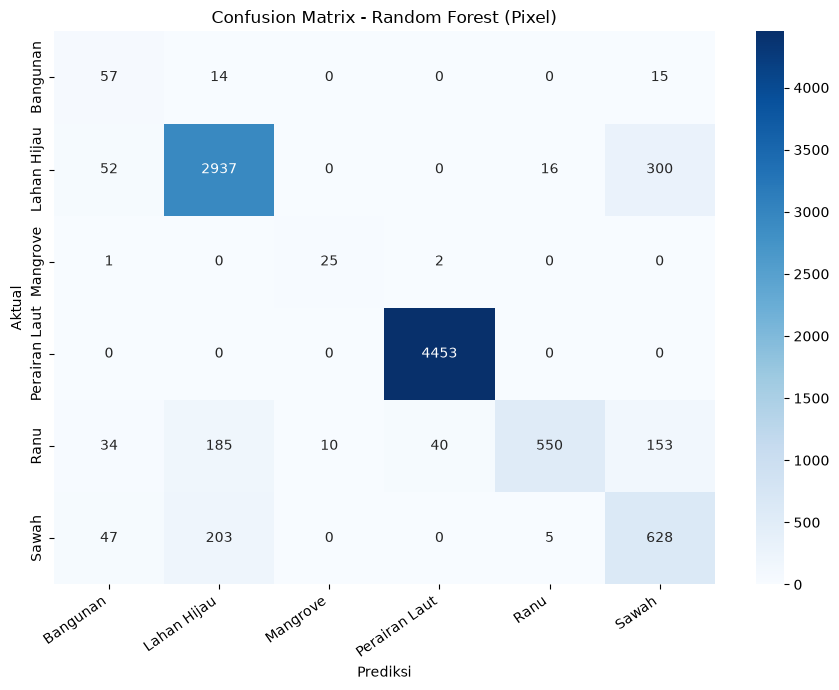

Model tersimpan sebagai model_lulc_jatim_pixel.pkl


In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

y_pred = model_rf.predict(X_test)
y_train_pred = model_rf.predict(X_train)

acc_train = accuracy_score(y_train, y_train_pred)
acc_test = accuracy_score(y_test, y_pred)
print(f"Akurasi training : {acc_train:.4f}")
print(f"Akurasi testing  : {acc_test:.4f}")
print(f"Selisih akurasi  : {abs(acc_train - acc_test):.4f}")
print(f"Macro F1 testing : {f1_score(y_test, y_pred, average='macro'):.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

kelas = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=kelas)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=kelas, yticklabels=kelas)
plt.title("Confusion Matrix - Random Forest (Pixel)")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig("visualisasi_confusion_matrix_piksel.png", dpi=300)
plt.show()

joblib.dump(model_rf, "model_lulc_jatim_pixel.pkl")
print("Model tersimpan sebagai model_lulc_jatim_pixel.pkl")


## 6. Deployment: Klasifikasi Setiap Piksel Citra

Model memprediksi kelas untuk setiap piksel citra. Prediksi dilakukan per blok agar penggunaan memori lebih terkendali. Piksel tanpa data valid diberi nilai 255 (nodata).

In [67]:
import folium
import matplotlib.colors as mcolors
import numpy as np
import rasterio
from jinja2 import Template
from rasterio.warp import transform_bounds

output_tif = "hasil_citra_uts_v2/openEO.tif"
output_html = "peta_klasifikasi_spasial_jatim.html"

# Pastikan model_rf sudah ada
if "model_rf" not in globals():
  raise ValueError(
      "Model Random Forest ('model_rf') belum didefinisikan di environment"
      " Anda. Latih model terlebih dahulu!"
  )

# 1. Membaca raster citra input
with rasterio.open(output_tif) as src:
  data_raster = src.read([1, 2, 3, 4, 5]).astype("float32")
  bounds = src.bounds
  transform = src.transform
  height, width = src.shape

  left, bottom, right, top = transform_bounds(
      src.crs, "EPSG:4326", bounds.left, bounds.bottom, bounds.right, bounds.top
  )
  img_bounds = [[bottom, left], [top, right]]

# 2. Reshape data raster
num_bands, h, w = data_raster.shape
pixels_2d = data_raster.reshape(num_bands, -1).T  # Bentuk: (Total Piksel, 5)

print(
    "Total piksel yang akan diprediksi:"
    f" {pixels_2d.shape[0]:,} piksel. Memulai prediksi bertahap (batching)..."
)

# 3. Prediksi Bertahap (Batch Prediction) untuk Mencegah MemoryError
batch_size = 50000  # Jumlah baris piksel per batch
pred_labels_list = []

for i in range(0, pixels_2d.shape[0], batch_size):
  batch_pixels = pixels_2d[i : i + batch_size]

  b02 = batch_pixels[:, 0]
  b03 = batch_pixels[:, 1]
  b04 = batch_pixels[:, 2]
  b08 = batch_pixels[:, 3]
  b11 = batch_pixels[:, 4]

  # Hitung indeks per batch
  ndvi = (b08 - b04) / (b08 + b04 + 1e-6)
  ndwi = (b03 - b08) / (b03 + b08 + 1e-6)
  ndbi = (b11 - b08) / (b11 + b08 + 1e-6)
  mndwi = (b03 - b11) / (b03 + b11 + 1e-6)

  # Sesuaikan urutan fitur ini persis dengan X_train saat training model Anda!
  X_batch = np.column_stack([b02, b03, b04, b08, b11, ndvi, ndwi, ndbi, mndwi])
  X_batch = np.nan_to_num(X_batch, nan=0.0, posinf=0.0, neginf=0.0)

  # Prediksi batch saat ini
  preds = model_rf.predict(X_batch)
  pred_labels_list.append(preds)

# Gabungkan kembali hasil seluruh batch
pred_labels = np.concatenate(pred_labels_list)
peta_prediksi = pred_labels.reshape(h, w)
print("Prediksi spasial selesai!")

# Mapping warna untuk setiap kelas
colors = {
    "Sawah": "#F4D03F",
    "Bangunan": "#E74C3C",
    "Lahan Hijau": "#27AE60",
    "Ranu": "#3498DB",
    "Perairan Laut": "#1B4F72",
    "Mangrove": "#8E44AD",
}

display_names = {
    "Sawah": "Sawah",
    "Bangunan": "Bangunan",
    "Lahan Hijau": "Hutan",
    "Ranu": "Danau",
    "Perairan Laut": "Laut",
    "Mangrove": "Mangrove",
}

# 4. Inisialisasi Peta Folium
center_lat = -7.5361
center_lon = 112.2384
m2 = folium.Map(location=[center_lat, center_lon], zoom_start=8, tiles=None)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles &copy; Esri",
    name="Esri Satellite",
    overlay=False,
).add_to(m2)
folium.TileLayer(
    "OpenStreetMap", name="OpenStreetMap", overlay=False
).add_to(m2)

# 5. Buat Layer Spasial per Kelas
classes_in_model = list(model_rf.classes_)

for label_str, hex_color in colors.items():
  target_val = None
  if label_str in classes_in_model:
    target_val = label_str
  else:
    mapping_urutan = [
        "Sawah",
        "Bangunan",
        "Lahan Hijau",
        "Mangrove",
        "Ranu",
        "Perairan Laut",
    ]
    if label_str in mapping_urutan:
      idx_val = mapping_urutan.index(label_str)
      if idx_val in classes_in_model:
        target_val = idx_val

  if target_val is None:
    continue

  rgba_img = np.zeros((height, width, 4), dtype=np.uint8)
  rgb = mcolors.to_rgb(hex_color)
  rgb_255 = (np.array(rgb) * 255).astype(np.uint8)

  mask = peta_prediksi == target_val
  rgba_img[mask, 0] = rgb_255[0]
  rgba_img[mask, 1] = rgb_255[1]
  rgba_img[mask, 2] = rgb_255[2]
  rgba_img[mask, 3] = 180  # Opasitas

  folium.raster_layers.ImageOverlay(
      image=rgba_img,
      bounds=img_bounds,
      opacity=1.0,
      name=f"Klasifikasi {display_names.get(label_str, label_str)}",
      control=True,
  ).add_to(m2)

# 6. Desain Legenda Kustom
legend_html = """
<div style="
    position: fixed; 
    bottom: 30px; left: 30px; width: 260px; height: auto; 
    background-color: white; z-index:9999; font-family: sans-serif;
    border-radius: 12px; padding: 18px 20px;
    box-shadow: 0 8px 20px rgba(0,0,0,0.15);">
    
    <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 12px;">
        <span style="font-size: 15px; font-weight: bold; color: #0b3c5d;">Klasifikasi Spasial Jatim</span>
        <span style="background-color: #EAECEE; color: #5D6D7E; font-size: 11px; font-weight: bold; padding: 3px 8px; border-radius: 6px;">Random Forest</span>
    </div>
    
    <hr style="border: none; border-top: 1px solid #E5E7E9; margin: 10px 0 14px 0;">
    
    <div style="font-size: 14px; color: #2C3E50; line-height: 2.2;">
        <div style="display: flex; align-items: center;"><span style="background: #F4D03F; width: 14px; height: 14px; display: inline-block; border-radius: 3px; margin-right: 12px;"></span> Sawah</div>
        <div style="display: flex; align-items: center;"><span style="background: #E74C3C; width: 14px; height: 14px; display: inline-block; border-radius: 3px; margin-right: 12px;"></span> Bangunan</div>
        <div style="display: flex; align-items: center;"><span style="background: #27AE60; width: 14px; height: 14px; display: inline-block; border-radius: 3px; margin-right: 12px;"></span> Hutan</div>
        <div style="display: flex; align-items: center;"><span style="background: #3498DB; width: 14px; height: 14px; display: inline-block; border-radius: 3px; margin-right: 12px;"></span> Danau</div>
        <div style="display: flex; align-items: center;"><span style="background: #1B4F72; width: 14px; height: 14px; display: inline-block; border-radius: 3px; margin-right: 12px;"></span> Laut</div>
        <div style="display: flex; align-items: center;"><span style="background: #8E44AD; width: 14px; height: 14px; display: inline-block; border-radius: 3px; margin-right: 12px;"></span> Mangrove</div>
    </div>
</div>
"""


class MacroElementLegend(folium.MacroElement):

  def __init__(self):
    super().__init__()
    self._template = Template(legend_html)


m2.add_child(MacroElementLegend())
folium.LayerControl(collapsed=False).add_to(m2)

m2.save(output_html)
print(
    f"Peta klasifikasi spasial seluruh Jawa Timur berhasil disimpan ke"
    f" '{output_html}'."
)

Total piksel yang akan diprediksi: 8,469,981 piksel. Memulai prediksi bertahap (batching)...


c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\LENOVO\miniforge3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  

Prediksi spasial selesai!
Peta klasifikasi spasial seluruh Jawa Timur berhasil disimpan ke 'peta_klasifikasi_spasial_jatim.html'.
